# 02a · Preprocesamiento: calidad visual y contexto temporal

## Motivación / Objetivos

Es la primera fase del preprocesamiento. Las fases siguientes (clima, detección, anotación y evaluación) tienen que trabajar sobre **los mismos fotogramas válidos**, cada uno con su contexto temporal.

Objetivos, para cada imagen capturada:
- Calcular la calidad visual (resolución, brillo y nitidez) con `src/calidad.py`.
- Añadir el contexto temporal con `src/tiempo.py`:
    - `timestamp` (UTC, del nombre del fichero) y `timestamp_local` (Madrid).
    - `time_slot_2h` y `day_type` (laborable / fin_de_semana / festivo) en hora local.
    - `illumination` (día / crepúsculo / noche) por elevación solar. Es independiente del clima, que etiqueta `02b`.
- Filtrar las imágenes no válidas y las cámaras en lista negra.
- Muestrear como máximo un fotograma por cámara cada X segundos, siendo X el refresco medido en `00b`: no tiene sentido muestrear más rápido de lo que la cámara publica imágenes nuevas.

**Objetivos del TFM relacionados:** OE-7 (iluminación, tipo de día y calidad como contextos de evaluación) y OE-4 (muestreo según el refresco medido).

## Método

Umbrales y parámetros en `config.yaml` (`calidad`, `muestreo`, `iluminacion`).

1. Configuración.
2. Métricas de calidad y contexto temporal por imagen.
3. Criterios de calidad y lista negra.
4. Fotogramas válidos y muestreo temporal.
5. Exportación de la fase `frames`.

### 1. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from calidad import add_quality, camera_blacklist, image_metrics, list_camera_images
from config import load_config, path, relative
from pipeline import sample_every, sampling_seconds, save_phase
from tiempo import day_type, illumination, load_holidays, parse_timestamp_from_name, time_slot_2h, to_local

CFG = load_config()
RAW_DIR = path("raw")
BLACKLIST_FILE = path("fases") / "blacklist_camaras.csv"

HOLIDAYS = load_holidays(path("festivos"))
LAT, LON = CFG["ubicacion"]["lat"], CFG["ubicacion"]["lon"]
TWILIGHT = CFG["iluminacion"]["elevacion_crepusculo"]

FRAME_SAMPLE_SECONDS, sampling_source = sampling_seconds()

print(f"Directorio de imágenes: {RAW_DIR}")
print(f"Festivos cargados: {len(HOLIDAYS)}")
print(f"Muestreo temporal: {FRAME_SAMPLE_SECONDS} s ({sampling_source})")

Directorio de imágenes: C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\raw
Festivos cargados: 28
Muestreo temporal: 6 s (refresco medido (00b))


### 2. Métricas de calidad y contexto temporal por imagen

In [2]:
image_files = list_camera_images(RAW_DIR)
print("Imágenes encontradas:", len(image_files))

rows = []
for img_path in image_files:
    try:
        metrics = image_metrics(img_path)
    except ValueError:
        continue

    ts = parse_timestamp_from_name(img_path.name)
    ts_local = to_local(ts)
    metrics.update({
        "path": relative(img_path),
        "timestamp": ts,
        "timestamp_local": ts_local,
        "time_slot_2h": time_slot_2h(ts_local),
        "day_type": day_type(ts_local, HOLIDAYS),
        "illumination": illumination(ts, LAT, LON, TWILIGHT),
    })
    rows.append(metrics)

image_quality_df = pd.DataFrame(rows)
print("Imágenes analizadas:", len(image_quality_df))
print("Sin marca de tiempo:", image_quality_df["timestamp"].isna().sum())
display(image_quality_df.head())

Imágenes encontradas: 78957


Imágenes analizadas: 78928
Sin marca de tiempo: 0


,camera,image,width,height,brightness,sharpness,path,timestamp,timestamp_local,time_slot_2h,day_type,illumination
0,21536,20261012T230457Z.jpg,640,480,83.618128,2324.126888,data/malaga/raw/21536/20261012T230457Z.jpg,2026-10-12 23:04:57,2026-10-13 01:04:57,00:00-02:00,laborable,noche
1,21537,20261012T230608Z.jpg,640,480,84.130059,1805.517781,data/malaga/raw/21537/20261012T230608Z.jpg,2026-10-12 23:06:08,2026-10-13 01:06:08,00:00-02:00,laborable,noche
2,21538,20261012T230623Z.jpg,640,480,78.956016,2398.202407,data/malaga/raw/21538/20261012T230623Z.jpg,2026-10-12 23:06:23,2026-10-13 01:06:23,00:00-02:00,laborable,noche
3,21539,20261012T230624Z.jpg,640,480,64.103757,2292.118519,data/malaga/raw/21539/20261012T230624Z.jpg,2026-10-12 23:06:24,2026-10-13 01:06:24,00:00-02:00,laborable,noche
4,21541,20260825T145146Z.jpg,640,480,85.769587,3460.784416,data/malaga/raw/21541/20260825T145146Z.jpg,2026-08-25 14:51:46,2026-08-25 16:51:46,16:00-18:00,laborable,dia


### 3. Criterios de calidad y lista negra

- El brillo mínimo solo se exige a las imágenes de día.
- El umbral de nitidez es un percentil de la distribución observada.
- Una cámara entra en la lista negra solo si falla más del `max_fraccion_fallos` de sus imágenes de día: una imagen aislada mala no descarta la cámara.

La lista negra se recalcula en cada ejecución (no se acumula), de modo que una cámara que mejora vuelve a entrar.

In [3]:
image_quality_df, thresholds = add_quality(image_quality_df, CFG["calidad"])
print("Umbrales:", thresholds)
print("\nImágenes válidas por iluminación:")
display(image_quality_df.groupby("illumination")["valid"].agg(["size", "mean"]))

camera_stats = camera_blacklist(image_quality_df, CFG["calidad"]["max_fraccion_fallos"])
BLACKLIST_FILE.parent.mkdir(parents=True, exist_ok=True)
camera_stats.to_csv(BLACKLIST_FILE, index=False)

blacklisted = set(camera_stats.loc[camera_stats["en_lista_negra"], "camera"])
print(f"\nCámaras en lista negra: {len(blacklisted)} de {len(camera_stats)} -> {BLACKLIST_FILE}")
display(camera_stats.sort_values("fraccion_fallos", ascending=False).head(10))

Umbrales: {'sharpness_min': 1837.9083138071862, 'brightness_min_dia': 30, 'brightness_max': 220}

Imágenes válidas por iluminación:


,size,mean
illumination,,
crepusculo,611,0.918167
dia,62660,0.988350
noche,15657,0.797726



Cámaras en lista negra: 0 de 129 -> C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\fases\blacklist_camaras.csv


,camera,n_imagenes,fraccion_fallos,en_lista_negra
3,21545,3231,0.082946,False
45,21587,2463,0.071458,False
0,21541,2740,0.028832,False
40,21582,2461,0.019911,False
5,21547,3253,0.019367,False
31,21573,2462,0.008936,False
22,21564,2460,0.008537,False
128,78681,2462,0.008123,False
12,21554,2459,0.005287,False
53,21595,2463,0.002436,False


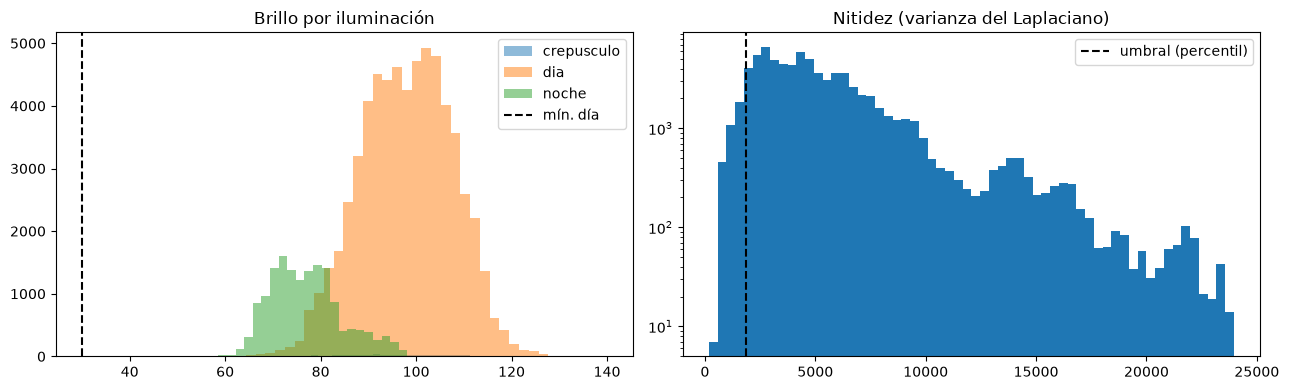

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for illum, group in image_quality_df.groupby("illumination"):
    axes[0].hist(group["brightness"], bins=40, alpha=0.5, label=illum)
axes[0].axvline(thresholds["brightness_min_dia"], color="k", ls="--", label="mín. día")
axes[0].set_title("Brillo por iluminación")
axes[0].legend()
axes[1].hist(image_quality_df["sharpness"], bins=60, log=True)
axes[1].axvline(thresholds["sharpness_min"], color="k", ls="--", label="umbral (percentil)")
axes[1].set_title("Nitidez (varianza del Laplaciano)")
axes[1].legend()
plt.tight_layout()
plt.show()

### 4. Fotogramas válidos y muestreo temporal

In [5]:
valid = image_quality_df[image_quality_df["valid"] & ~image_quality_df["camera"].isin(blacklisted)]
frames = sample_every(valid, FRAME_SAMPLE_SECONDS)
frames["frame_interval_seconds"] = FRAME_SAMPLE_SECONDS

print("Fotogramas válidos antes de muestreo:", len(valid))
print("Fotogramas tras muestreo temporal:", len(frames))
for col in ["day_type", "time_slot_2h", "illumination"]:
    print(f"\n{col}:\n{frames[col].value_counts(dropna=False).sort_index().to_string()}")

Fotogramas válidos antes de muestreo: 74981
Fotogramas tras muestreo temporal: 74508

day_type:
day_type
fin_de_semana    16845
laborable        57663

time_slot_2h:
time_slot_2h
00:00-02:00     1501
02:00-04:00     2092
04:00-06:00     2093
06:00-08:00     3451
08:00-10:00     3252
10:00-12:00     6970
12:00-14:00    12456
14:00-16:00    13579
16:00-18:00     7747
18:00-20:00    16569
20:00-22:00     1968
22:00-00:00     2830

illumination:
illumination
crepusculo      561
dia           61538
noche         12409


### 5. Exportación de la fase `frames`

Las fases `weather` y `detections` se escriben en ficheros propios y se unen por `(camera, image)` con `pipeline.load_frames()`.

In [6]:
export_cols = [
    "camera",
    "image",
    "path",
    "timestamp",
    "timestamp_local",
    "time_slot_2h",
    "day_type",
    "illumination",
    "width",
    "height",
    "brightness",
    "sharpness",
    "quality_score",
    "frame_interval_seconds",
]
out = save_phase(frames[export_cols], "frames")
print(f"Fase frames: {len(frames)} fotogramas -> {out}")
display(frames[export_cols].head(10))

Fase frames: 74508 fotogramas -> C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\fases\frames.parquet


,camera,image,path,timestamp,timestamp_local,time_slot_2h,day_type,illumination,width,height,brightness,sharpness,quality_score,frame_interval_seconds
0,21536,20261012T230457Z.jpg,data/malaga/raw/21536/20261012T230457Z.jpg,2026-10-12 23:04:57,2026-10-13 01:04:57,00:00-02:00,laborable,noche,640,480,83.618128,2324.126888,0.155781,6
1,21538,20261012T230623Z.jpg,data/malaga/raw/21538/20261012T230623Z.jpg,2026-10-12 23:06:23,2026-10-13 01:06:23,00:00-02:00,laborable,noche,640,480,78.956016,2398.202407,0.137512,6
2,21539,20261012T230624Z.jpg,data/malaga/raw/21539/20261012T230624Z.jpg,2026-10-12 23:06:24,2026-10-13 01:06:24,00:00-02:00,laborable,noche,640,480,64.103757,2292.118519,0.074680,6
3,21541,20260825T145146Z.jpg,data/malaga/raw/21541/20260825T145146Z.jpg,2026-08-25 14:51:46,2026-08-25 16:51:46,16:00-18:00,laborable,dia,640,480,85.769587,3460.784416,0.301136,6
4,21541,20260825T155429Z.jpg,data/malaga/raw/21541/20260825T155429Z.jpg,2026-08-25 15:54:29,2026-08-25 17:54:29,16:00-18:00,laborable,dia,640,480,82.288542,3019.893123,0.240432,6
5,21541,20260825T155459Z.jpg,data/malaga/raw/21541/20260825T155459Z.jpg,2026-08-25 15:54:59,2026-08-25 17:54:59,16:00-18:00,laborable,dia,640,480,83.078304,3057.625727,0.248933,6
6,21541,20260825T155529Z.jpg,data/malaga/raw/21541/20260825T155529Z.jpg,2026-08-25 15:55:29,2026-08-25 17:55:29,16:00-18:00,laborable,dia,640,480,82.717002,3065.285165,0.247625,6
7,21541,20260825T155559Z.jpg,data/malaga/raw/21541/20260825T155559Z.jpg,2026-08-25 15:55:59,2026-08-25 17:55:59,16:00-18:00,laborable,dia,640,480,82.600563,3076.113647,0.247823,6
8,21541,20260825T155629Z.jpg,data/malaga/raw/21541/20260825T155629Z.jpg,2026-08-25 15:56:29,2026-08-25 17:56:29,16:00-18:00,laborable,dia,640,480,81.463122,3013.086835,0.234286,6
9,21541,20260825T155659Z.jpg,data/malaga/raw/21541/20260825T155659Z.jpg,2026-08-25 15:56:59,2026-08-25 17:56:59,16:00-18:00,laborable,dia,640,480,82.944600,2979.819685,0.238417,6


## Salida / Resultados

| Salida | Contenido |
|---|---|
| `data/malaga/fases/frames.parquet` | Fotogramas válidos con calidad y contexto temporal. |
| `data/malaga/fases/blacklist_camaras.csv` | Fracción de fallos diurnos por cámara y si está en lista negra. |

**Última ejecución (datos hasta el 17/10/2026):**
- 78.957 imágenes encontradas y 78.928 analizadas, todas con marca de tiempo.
- Umbral de nitidez: 1.838. Válidas: 98,8 % de día, 91,8 % en crepúsculo y 79,8 % de noche.
- Lista negra: 0 de 129 cámaras. La que más falla es la 21545 (8,3 % de sus imágenes de día).
- 74.981 imágenes válidas → **74.508 fotogramas** tras el muestreo a 6 s: 57.663 laborables y 16.845 de fin de semana.

## Observaciones

- **Posible sesgo nocturno:** el brillo solo se exige de día, pero el umbral de nitidez es global y las imágenes nocturnas son más borrosas. Se descarta el 20 % de las imágenes de noche frente al 1 % de día. Para OE-7 conviene valorar un umbral de nitidez por iluminación.
- **Cobertura temporal desigual:** los fotogramas salen de solo 10 días (25/08–07/09 y 13/10–17/10). Todo el "fin de semana" es un único sábado (17/10) y no hay ningún festivo, aunque `calendario_festivos_malaga.csv` incluye el 08/09 y el 12/10. Las comparaciones por tipo de día de `05` hay que tomarlas con cautela.
- Los festivos se leen de `data/malaga/calendario_festivos_malaga.csv`.